# Case FarmaSaúde

##Contexto e Problema

A FarmaSaúde atua no farmacêutico, veterinário e de bem-estar há mais de 10 anos, com unidades físicas distribuídas no Nordeste do Brasil e, mais recentemente, com vendas online para todo o país.

O mercado farmacêutico demonstrou grande resiliência e segue em expansão. Muitas pessoas mudaram seus hábitos de consumo durante o período de isolamento, passando a priorizar o autocuidado, a prevenção e a manutenção da saúde de forma mais rigorosa. O CEO da FarmaSaúde tem uma grande preocupação sobre como a empresa irá capturar e fidelizar essa fatia crescente do mercado.

Desde o início do ano passado, a FarmaSaúde iniciou um plano para acelerar a transformação digital da empresa e a estruturação dos dados dos clientes para melhorar sua jornada de compra. Com as análises realizadas, decidiram lançar um programa de fidelidade que permite identificar as compras dos clientes nas lojas físicas, canal onde possuem o maior volume de vendas e interação direta.

O CEO é analítico e orientado a resultados, participa ativamente das transformações da empresa e orienta o time nos planejamentos estratégicos. Ele proporciona um ambiente com total autonomia para o time realizar as mudanças necessárias e acompanha mensalmente, em comitê, os resultados das iniciativas. As expectativas sobre o retorno dessas transformações são altas.

O CEO me enviou algumas dúvidas estratégicas, pedindo minha ajuda para respondê-las:

## Questões Estratégicas
1. Previsão de Demanda: Queremos realizar o planejamento da venda de medicamentos para Adultos para os próximos seis meses. Qual a previsão de venda diária para essa categoria em nossas unidades?

2. Segmentação de Clientes: Sabemos que nem todos os clientes possuem o mesmo perfil; alguns geram um LTV (Lifetime Value) muito superior a outros. Podemos segregar os clientes em grupos específicos? Há algum segmento significativamente mais rentável?

3. Análise de Churn e Retenção: Uma das prioridades para o próximo ano é aumentar a retenção. Na companhia, consideramos o cliente inativo quando ele não realiza transações por mais de 90 dias. Qual seria o grupo alvo para ações de retenção? Ou seja: qual perfil de cliente apresenta o maior risco de churn?

4. Recomendação de Produtos: Com base no histórico de compras e no comportamento de navegação, quais outros produtos (como vitaminas, dermocosméticos ou itens de higiene) podemos oferecer de forma personalizada para cada cliente?

---

O projeto vai ser iniciado pela exploração dos dados cedidos pelo CEO, para então avançar para as perguntas estratégicas que ele me fez.

# Leitura e Interpretação dos Dados

In [118]:
import sys
sys.path.append("..")

In [119]:
import numpy as np
import pandas as pd
import datetime as  dt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from pathlib import Path

In [120]:
from src.data import load_data

In [121]:
path = "../data/raw/"
output_dir = Path("../charts_and_figures")
output_dir.mkdir(exist_ok=True)
sns.set_style("darkgrid")

In [122]:
from src.data import load_raw_tables    

customers_df, products_df, sales_df = load_raw_tables(str(path))

In [123]:
# Customer table
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105924 entries, 0 to 105923
Data columns (total 4 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   CUSTOMER_ID          105924 non-null  int64 
 1   SEX                  105924 non-null  object
 2   BIRTH_DATE           105924 non-null  object
 3   FIRST_PURCHASE_DATE  105924 non-null  object
dtypes: int64(1), object(3)
memory usage: 3.2+ MB


In [124]:
# Product table
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38303 entries, 0 to 38302
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   PRODUCT_ID  38303 non-null  int64 
 1   UNIT        38303 non-null  object
 2   LEVEL_1     25734 non-null  object
 3   LEVEL_2     25734 non-null  object
 4   LEVEL_3     25473 non-null  object
 5   LEVEL_4     23190 non-null  object
dtypes: int64(1), object(5)
memory usage: 1.8+ MB


In [125]:
# Sales table
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1859583 entries, 0 to 1859582
Data columns (total 7 columns):
 #   Column         Dtype  
---  ------         -----  
 0   SALE_ID        int64  
 1   SALE_DATE      object 
 2   CUSTOMER_ID    float64
 3   PRODUCT_ID     int64  
 4   QUANTITY       float64
 5   SALE_CATEGORY  object 
 6   BRANCH         int64  
dtypes: float64(2), int64(3), object(2)
memory usage: 99.3+ MB


In [126]:
from src.data import clean_tables

clean_tables(customers_df, products_df, sales_df)

(        CUSTOMER_ID  SEX BIRTH_DATE FIRST_PURCHASE_DATE
 0                 0  NaN 1900-01-01          2017-03-06
 1                 1  NaN 1900-01-01          2017-03-06
 2                 2  NaN 1900-01-01          2017-03-06
 3                 3  NaN 1900-01-01          2017-02-18
 4                 4  NaN 1900-01-01          2017-01-16
 ...             ...  ...        ...                 ...
 105919       105919    F 1977-09-11          2021-10-16
 105920       105920  NaN 1900-01-01          1900-01-01
 105921       105921  NaN 1900-01-01          1900-01-01
 105922       105922    F 1985-05-15          2021-10-16
 105923       105923    F 1986-09-23          2021-10-16
 
 [105924 rows x 4 columns],
        PRODUCT_ID UNIT LEVEL_1                  LEVEL_2  \
 0               0   UN   ADULT  NUTRITION AND DIETETICS   
 1               2   UN   ADULT  NUTRITION AND DIETETICS   
 2               3   UN     NaN                      NaN   
 3               4   UN   ADULT               

In [127]:
# Retirar espaço vazio nas strings dos niveis
from src.data import _first_word

products_df["LEVEL_1"] = products_df["LEVEL_1"].apply(_first_word)



In [128]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38303 entries, 0 to 38302
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   PRODUCT_ID  38303 non-null  int64 
 1   UNIT        38303 non-null  object
 2   LEVEL_1     25734 non-null  object
 3   LEVEL_2     25734 non-null  object
 4   LEVEL_3     25473 non-null  object
 5   LEVEL_4     23190 non-null  object
dtypes: int64(1), object(5)
memory usage: 1.8+ MB


In [129]:
# Distribuição percentual de cada nivel 2 nos niveis 1
n1_n2 = (products_df.groupby("LEVEL_1")['LEVEL_2'].value_counts()/products_df.groupby("LEVEL_1")['LEVEL_2'].count()).reset_index(0)

# 'LEVEL_2' is currently the index, not a column. Reset index to convert it to a column.
n1_n2.reset_index(inplace=True)

# The percentage values are in the column named '0'. Rename it to 'value'.
n1_n2.rename(columns={0: 'value'}, inplace=True)

# Round the values as intended.
n1_n2['value'] = n1_n2['value'].round(3)

fig = px.bar(n1_n2, x = 'LEVEL_1', y = 'value', color='LEVEL_2',labels={"value":"Percentage (%)"},template="seaborn")
fig.update_layout(title={'text':'Product composition based on Main Category','x':0.25})
output_file = output_dir / "product_composition.png"
fig.write_image(output_file)
fig.show()

Insights:
- PharmaSaude has good amount of its sales, based on the sample, of nutirion and dietetics products for all the expected segments (elderly, baby and pregnant). The sample has not shown any signals of medication sold at PharmaSaude, which is unusual for a pharma. 

---
# 1. Demand Forecast

In [130]:
total_sales= sales_df[['SALE_DATE','QUANTITY']].groupby('SALE_DATE').sum()
total_sales.index = pd.to_datetime(total_sales.index)

In [131]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=total_sales.index, y=total_sales['QUANTITY'],
                  mode='lines',
                  name='Real'))
fig.update_layout(title={'text':'Total Sales Over Time','x':0.25})

fig.show()
fig.write_image(output_dir / "total_sales_over_time.png")

Insights:
- Indices of sazonal cycles - it looks like PharmaSaude has sazonal peaks every 2 weeks. As this is a sample of the data, would be reasonable to investigate. 
- Data of a shor period - around one year of data. 
- There is a peak of sales in April of 2021. 

<Axes: ylabel='BRANCH'>

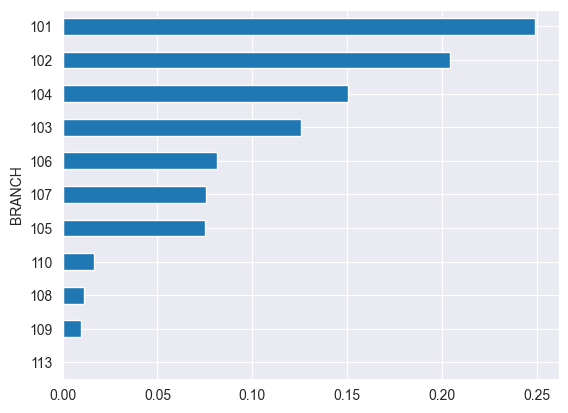

In [132]:
sales_df['BRANCH'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

AttributeError: 'Figure' object has no attribute 'write_image'

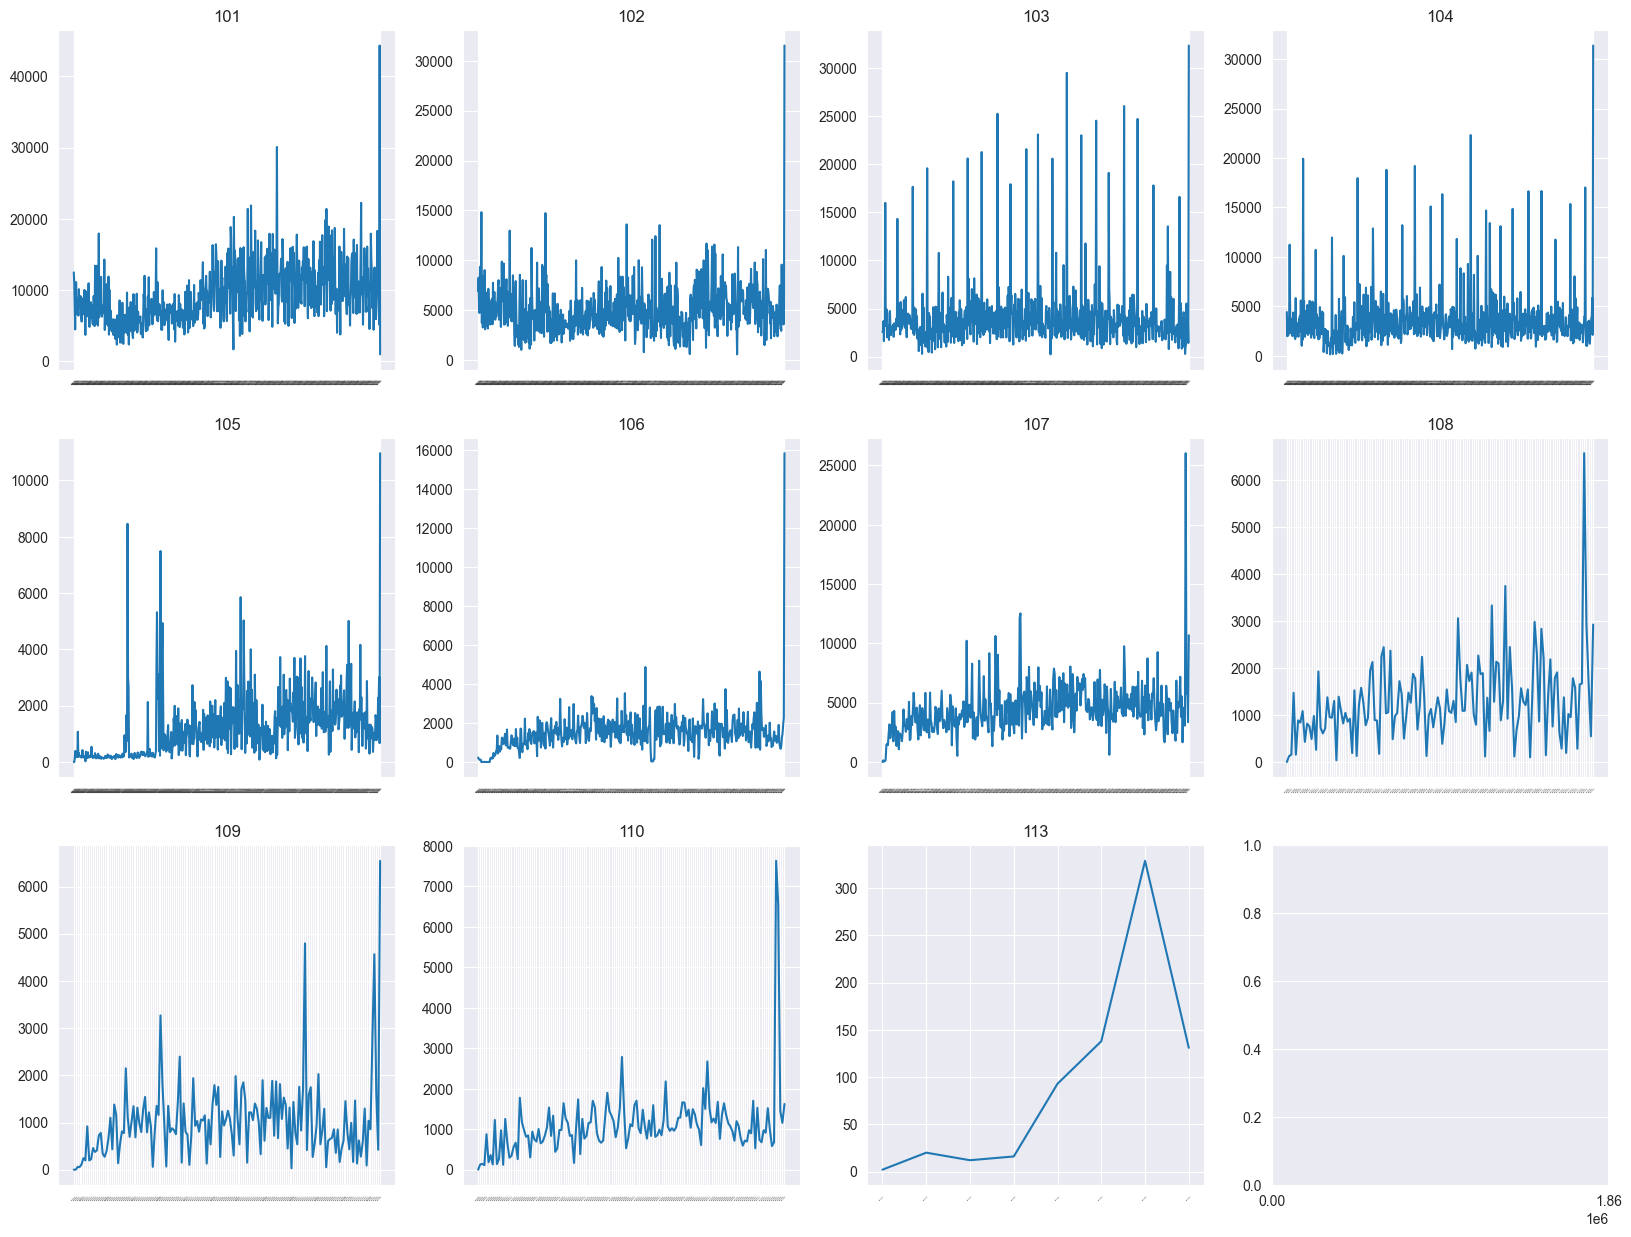

In [ ]:
branches = sorted(sales_df["BRANCH"].dropna().astype(str).unique())
n_branches = len(branches)
n_cols = 4
n_rows = max(1, int(np.ceil(n_branches / n_cols)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows), squeeze=False)
axes = axes.flatten()

for ax, branch in zip(axes, branches):
    sales_df_plot = (
        sales_df.loc[sales_df["BRANCH"].astype(str) == branch, ["SALE_DATE", "QUANTITY"]]
        .groupby("SALE_DATE")
        .sum()
        .sort_index()
    )
    sales_df_plot.index = pd.to_datetime(sales_df_plot.index)

    ax.plot(sales_df_plot.index, sales_df_plot["QUANTITY"].values, linewidth=1.5)
    ax.set_title(branch)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.set_xlabel("Sale Date")
    ax.set_ylabel("Quantity")

for ax in axes[n_branches:]:
    ax.axis("off")

fig.suptitle("Sales by Branch", y=1.02)
fig.tight_layout()
fig.savefig(output_dir / "sales_by_branch.png", dpi=300, bbox_inches="tight")
plt.show()

- There is only one branch in the sample, should have more than one on the raw data.

In [134]:
daily_total = total_sales[['QUANTITY']].asfreq('D')
daily_total.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 664 entries, 2020-01-02 to 2021-10-26
Freq: D
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   QUANTITY  663 non-null    float64
dtypes: float64(1)
memory usage: 10.4 KB


In [135]:
daily_total[daily_total.QUANTITY.isna()]

,QUANTITY
SALE_DATE,
2020-02-25,NaN


- It seems that PharmaSaude didnt had any sales in 28 days in this sample data.

## Sales to Adults

In [136]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.graphics.tsaplots import plot_acf
from scipy.signal import periodogram
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess
import datetime as dt
from prophet import Prophet
import statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.multioutput import MultiOutputRegressor

In [137]:
prod_sale = sales_df.merge(products_df, on = 'PRODUCT_ID', how = 'left')
prod_sale

,SALE_ID,SALE_DATE,CUSTOMER_ID,PRODUCT_ID,QUANTITY,SALE_CATEGORY,BRANCH,UNIT,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
0,0,2021/02/10,45659.0,17631,1.0,E-COMMERCE,101,NaN,NaN,NaN,NaN,NaN
1,0,2021/02/10,45659.0,34575,1.0,E-COMMERCE,101,UN,ADULT,NUTRITION AND DIETETICS,BARS AND NUTRITIOUS SNACKS,DIETARY COOKIES AND SNACKS
2,1,2021/02/12,70766.0,2240,1.0,E-COMMERCE,101,NaN,NaN,NaN,NaN,NaN
3,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
4,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
...,...,...,...,...,...,...,...,...,...,...,...,...
3924145,854530,2021/10/23,NaN,36642,10.0,Loja,113,UN,CHILDREN,NUTRITION AND DIETETICS,FOOD SUPPLEMENTS,MOIST AND PASTY FOODS
3924146,854530,2021/10/23,NaN,7332,10.0,Loja,113,UN,CHILDREN,NUTRITION AND DIETETICS,FOOD SUPPLEMENTS,MOIST AND PASTY FOODS
3924147,854530,2021/10/23,NaN,7333,10.0,Loja,113,NaN,NaN,NaN,NaN,NaN
3924148,854531,2021/10/23,106865.0,7528,1.0,Loja,113,UN,ADULT,NUTRITION AND DIETETICS,BARS AND NUTRITIOUS SNACKS,TOOTHPICKS AND ORAL ACCESSORIES


In [138]:
adult_sale= prod_sale[prod_sale['LEVEL_1']== 'ADULT']
adult_sale

,SALE_ID,SALE_DATE,CUSTOMER_ID,PRODUCT_ID,QUANTITY,SALE_CATEGORY,BRANCH,UNIT,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
1,0,2021/02/10,45659.0,34575,1.0,E-COMMERCE,101,UN,ADULT,NUTRITION AND DIETETICS,BARS AND NUTRITIOUS SNACKS,DIETARY COOKIES AND SNACKS
3,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
4,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
5,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
6,2,2021/02/12,42579.0,17707,1.0,E-COMMERCE,101,UN,ADULT,PHARMACY,VITAMINS AND SUPPLEMENTS,VITAMINS AND SUPPLEMENTS
...,...,...,...,...,...,...,...,...,...,...,...,...
3924138,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS
3924139,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS
3924140,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS
3924141,854528,2021/10/24,106864.0,31589,1.0,Loja,113,UN,ADULT,PERFUMERY AND COSMETICS,HYGIENE AND CLEANING,COLLECTORS AND CONTAINERS


<Axes: ylabel='SALE_CATEGORY'>

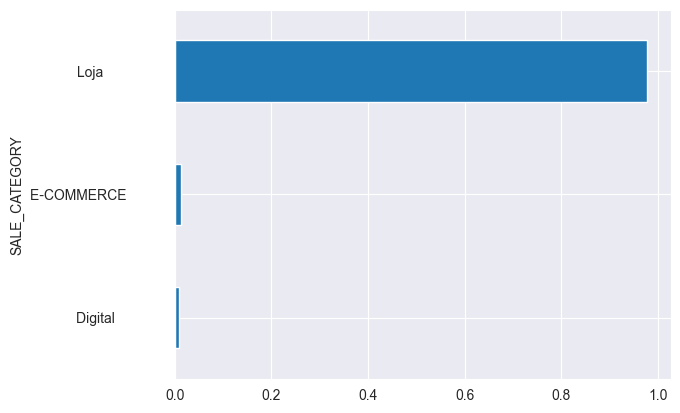

In [139]:
adult_sale['SALE_CATEGORY'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

<Axes: ylabel='BRANCH'>

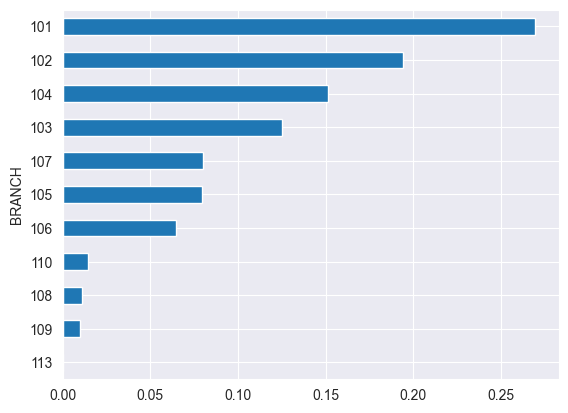

In [140]:
adult_sale['BRANCH'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

In [141]:
hist_adult= adult_sale[['SALE_DATE','QUANTITY']].groupby('SALE_DATE').sum()

fig=go.Figure()
fig.add_trace(go.Scatter(x=hist_adult.index, y= hist_adult['QUANTITY'], mode='lines', name='Real'))
fig.update_layout(title={'text':'Histogram of Adult Sales','x':0.25})
fig.show()

fig.write_image(output_dir / "hist_adult_sales.png")
#

- There is an outlier on April 30th of 2021
- There is an increase trendline from September of 2020 to April of 2021, 

## Sazonal Cycle Analysis
Para a análise dos ciclos sazonais diversos estratégias podem ser utilizadas. Aqui são realizadas:

- Autocorrelograma parcial
- Periodograma - decomposição em séries de Fourier e análise de cada um dos coeficientes
- Decomposição de série temporal

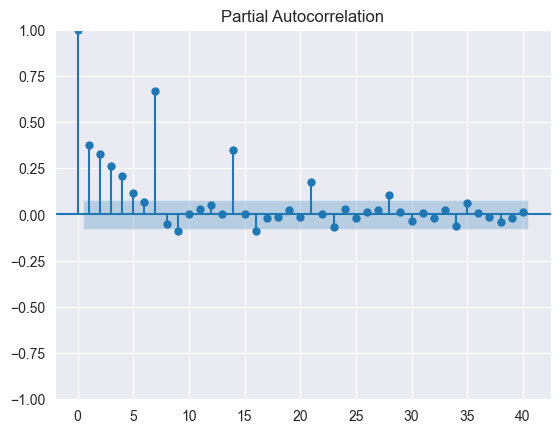

In [142]:
plot_pacf(hist_adult, lags = 40)
plt.show()

**Autocorrelação Parcial(PACF):** Mede a correlação de uma série com ela mesma em diferentes defasagens (lags), removendo o efeito dos lags intermediários.

- Lag 0 → sempre 1.0, pois a série é perfeitamente correlacionada consigo mesma
- Lags 1 a 4 → correlações positivas e significativas (~0.35, 0.25, 0.20, 0.10) — indicam que os valores recentes influenciam diretamente o valor atual.
- Lag 7/8 → pico em ~0.68, bastante relevante — sugere um padrão semanal nos seus dados
- Lag 14/15 → outro pico menor (~0.35) — reforça o padrão semanal (2 semanas)
Demais lags → dentro da banda azul (intervalo de confiança de 95%) = estatisticamente não significativos

In [143]:
from src.features import plot_periodogram

<Axes: title={'center': 'Periodogram'}, ylabel='Variance'>

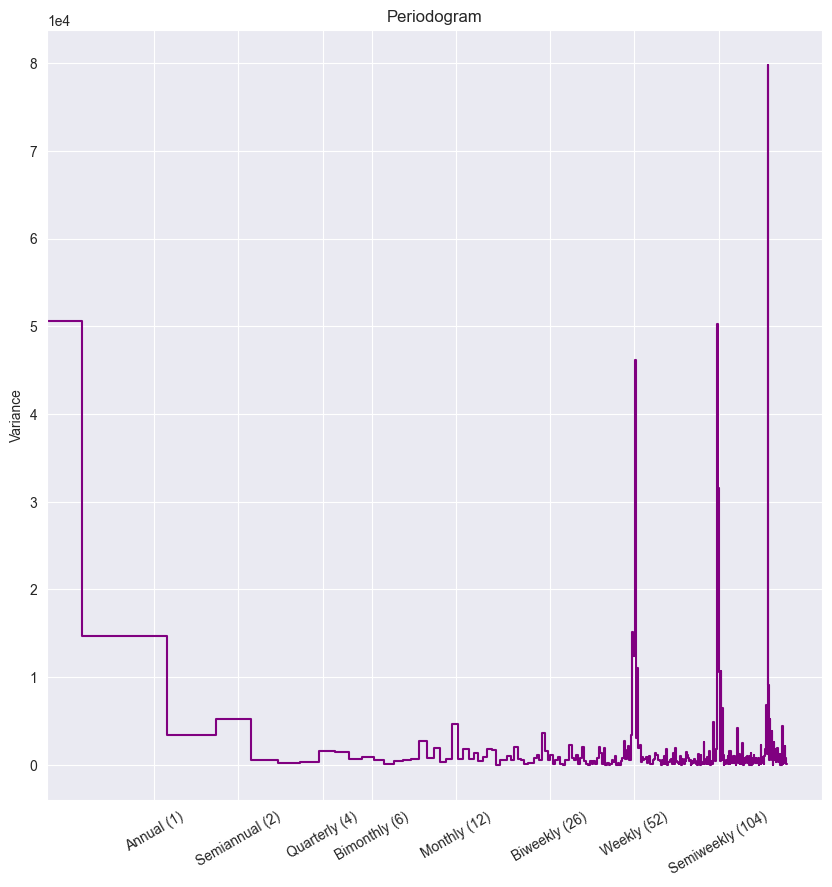

In [144]:
plot_periodogram(hist_adult.QUANTITY)

**Periodograma:** mostra quanta "energia" (variância) cada frequência contribui para a série temporal. É como decompor a série em ondas e ver quais têm mais força. Podemos ver uma forte recorrencia anual, bi semanal (lag 14 do PACF), semanal (lag 7 do PACF) e a recorrencia mais forte é semisemanal (a cada 3 ou 4 dias)

In [145]:
hist_adult.index = pd.to_datetime(hist_adult.index)
hist_adult.head()

,QUANTITY
SALE_DATE,
2020-01-02,3340.0
2020-01-03,3420.0
2020-01-04,4010.0
2020-01-05,2605.0
2020-01-06,3461.0


In [146]:
hist_adult.fillna(0, inplace = True)
decomposition = seasonal_decompose(hist_adult.QUANTITY)
# define os componentes
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# plots
plt.subplots(figsize=(10, 7))
plt.subplot(411)
plt.plot(hist_adult.QUANTITY, label='Original')
plt.legend(loc='best')
plt.margins(y=0.2)

plt.subplot(412)
plt.plot(trend, label='Trend')
plt.legend(loc='best')
plt.margins(y=0.2)

plt.subplot(413)
plt.plot(seasonal, label='Seasonality')
plt.legend(loc='best')
plt.margins(y=0.2)

plt.subplot(414)
plt.plot(residual, label='Residuals')
plt.legend(loc='best')
plt.margins(y=0.2)

ValueError: You must specify a period or x must be a pandas object with a PeriodIndex or a DatetimeIndex with a freq not set to None

## Feature Engineering

Criação de features temporais, ligadas as datas.

In [ ]:
def criaFeaturesTemporais(df):
    df = df.copy()
    df["Year"]      = df.index.year
    df["Month"]     = df.index.month
    df["Day"]       = df.index.day
    df["WeekDay"]   = df.index.weekday
    df["Quarter"]   = df.index.quarter
    df["DayOfYear"] = df.index.dayofyear
    df["WeekOfYear"] = df.index.isocalendar().week.astype(int)  # substituto do weekofyear
    return df

historico_adultos_temp = criaFeaturesTemporais(historico_adultos)

/tmp/ipykernel_1188/1372480768.py:11: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



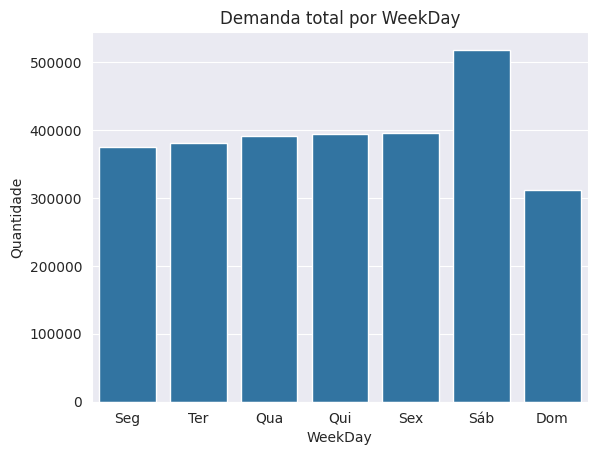

/tmp/ipykernel_1188/1372480768.py:11: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



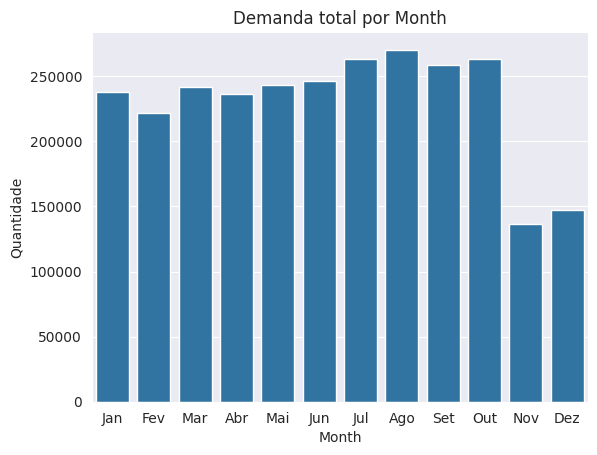

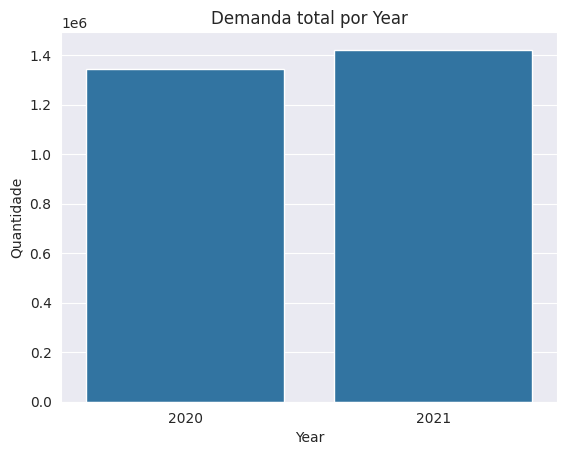

In [ ]:
labels = {
    "WeekDay": ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"],
    "Month":   ["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"],
    "Year":    None  # mantém os valores numéricos
}

for col in ["WeekDay", "Month", "Year"]:
    sales_df = historico_adultos_temp[[col, 'QUANTIDADE']].groupby(col).sum()
    ax = sns.barplot(x=sales_df.index, y=sales_df['QUANTIDADE'].values)
    if labels[col]:
        ax.set_xticklabels(labels[col])
    ax.set_title(f'Demanda total por {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Quantidade')
    plt.show()

A análise a partir das features temporais permite identificar:

- Uma sazonalidade semanal, já confirmada pelo autocorrelograma, com um claro número de vendas maior no sabádo (como se trata de loja física, se justifica, sendo um dia em que grande parte dos clientes deve ter disponibilidade para ir comprar na loja) e um número menor de vendas no domingo (onde pode-se imaginar que as lojas fecham mais cedo do que dias normais)

- Apesar do gráfico de análise mes a mes parecer indicar que existe uma menor quantidade de vendas nos últimos meses do ano deve-se atentar ao fato que os meses de novembro e dezembro de 2021 não se encontram na base hisórica, o que justificaria o comportamento observado.

In [ ]:
def criaFeaturesCorrelatas(df):
  df = df.copy()
  #Features auto correlacionadas
  df['lag_1'] = df['QUANTIDADE'].shift(1, freq = 'D')
  df['lag_7'] = df['QUANTIDADE'].shift(7, freq = 'D')
  df['lag_14'] = df['QUANTIDADE'].shift(14, freq = 'D')
  df['lag_21'] = df['QUANTIDADE'].shift(21, freq = 'D')
  df['lag_28'] = df['QUANTIDADE'].shift(28, freq = 'D')
  df['lag_56'] = df['QUANTIDADE'].shift(56, freq = 'D')
  df['rolling_mean_7'] = df['lag_1'].rolling(window=7).mean()
  df['rolling_mean_14'] = df['lag_1'].rolling(window=14).mean()
  df['rolling_mean_21'] = df['lag_1'].rolling(window=21).mean()
  df['rolling_mean_28'] = df['lag_1'].rolling(window=28).mean()
  df['rolling_mean_56'] = df['lag_1'].rolling(window=56).mean()
  return df


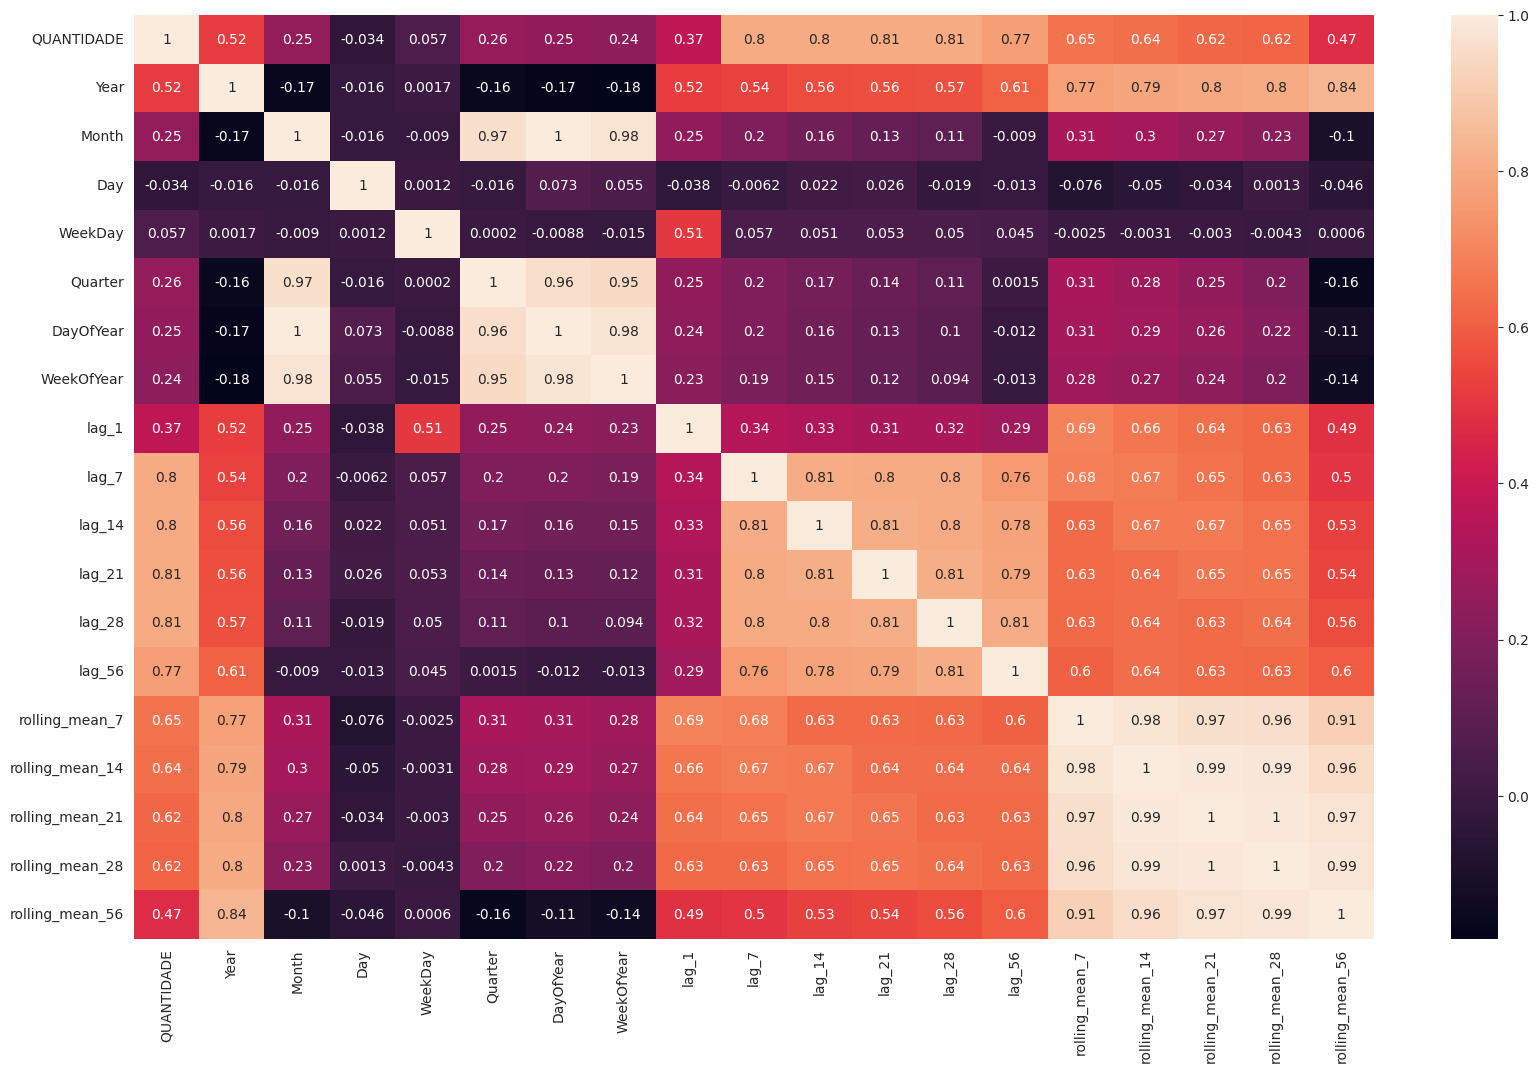

In [ ]:
#Correlation Heatmap

df_featured = criaFeaturesCorrelatas(criaFeaturesTemporais(historico_adultos))

plt.figure(figsize=(20,12))
corr = df_featured.corr()
sns.heatmap(corr, annot=True)
plt.show()

Podemos ver uma alta correlação entre os lags 7,14,21 e 28. Isso significa que a demanda da semana anterior explica muito bem a da semana atual.
A forte correlação com o Lag 56 também denota um forte padrão bimestral nas vendas.
A média movél (rolling mean) também explica bem a demanda, principalmente a Média movel dos ultimos 7 dias (rolling_mean_7), que é um bom preditor a curto prazo.


---

# Modelagem

Para modelagem, vou utilizar os 2 modelos: SARIMAX e Prophet. Esses serão escolhidos pelo padrão sazonal dos dados. Separei a base de treino e teste respeitando a váriavel temporal. Assim os últimos 180 dias (6 meses em frequência diária) foram utilizados como base de treino.

Observações:

A forma como o split foi realizado aloca poucos dados para o treinamento, o que pode comprometer a performance do modelo e levar ao overfit nos dados disponíveis. Além disso, nesse split não foi feita a separação de uma base de validação, e as métricas foram obtidas diretamente utilizando a base de testes. Embora essa abordagem não seja a ideal, ela se faz necessária devido à quantidade limitada de dados e ao grande horizonte temporal da previsão.

In [ ]:
fim_treino = adultos_diario.index.max()-pd.Timedelta(unit = 'D', value = 180)

In [ ]:
df_train = adultos_diario[:fim_treino]
df_test = adultos_diario[fim_treino+pd.Timedelta(unit = 'D', value = 1):]

In [ ]:
# tamanho da divisão:
print("Tamanho do conjunto de treino: ", df_train.shape)
print("Tamanho do conjunto de teste:  ", df_test.shape)
# visualização do set de treino
df_train.head()

Tamanho do conjunto de treino:  (483, 1)
Tamanho do conjunto de teste:   (180, 1)


,QUANTIDADE
DATA_VENDA,
2020-01-02,3340.0
2020-01-03,3420.0
2020-01-04,4010.0
2020-01-05,2605.0
2020-01-06,3461.0


In [ ]:
def calculo_erro(previsto, real):

    erro = previsto - real
    total_y = 0
    ape = 0
    for y, p in zip(real, previsto):
        if y > 0:
            ape += abs((y - p)/y)
            total_y += 1

    mape = ape/total_y

    resultados = {'MAPE': mape, 'MAE': np.mean(np.abs(erro))}

    print("=" * 30)
    print(f"{'MÉTRICAS DE ERRO':^30}")
    print("=" * 30)
    print(f"  MAPE: {mape:.2%}")
    print(f"  MAE:  {resultados['MAE']:,.2f}")
    print("=" * 30)

    return resultados

In [ ]:
metricas = {}

## Sarimax

In [ ]:
df_m = df_train.copy()
df_mt = df_test.copy()

In [ ]:
fourier_feat = FourierFeaturizer(m = 96, k = 5)
exog_train_sarimax  = fourier_feat.fit_transform(df_m)[1]
exog_train_sarimax.index = df_m.index

In [ ]:
model = auto_arima(y = df_m,
                  X = exog_train_sarimax,
                  method = 'nm',
                  max_D = 2,
                  stepwise = True,
                  maxiter = 50,
                  trace = True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8481.724, Time=0.68 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8281.526, Time=0.42 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8090.634, Time=0.52 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=7921.704, Time=0.90 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8293.808, Time=0.45 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=7948.521, Time=0.81 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=7913.887, Time=0.95 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=8384.121, Time=1.02 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=8287.489, Time=2.09 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=7922.139, Time=2.54 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=7909.186, Time=1.73 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=7915.332, Time=0.78 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=8348.731, Time=0.92 sec
 ARIMA(0,1,3)(0,0,0)[0]             : AIC=8285.424, Time=1.26 sec
 ARIMA(1,1,1)(0,0,0)[0]          

In [ ]:
model = sm.tsa.statespace.SARIMAX(endog = df_m,
                                  order=(0,1,2),
                                  exog = exog_train_sarimax,
                                  freq='D')
res = model.fit()

In [ ]:
exog_test_sarimax = fourier_feat.transform(X = df_mt, n_periods=df_mt.shape[0])[1]
exog_test_sarimax.index = df_mt.index

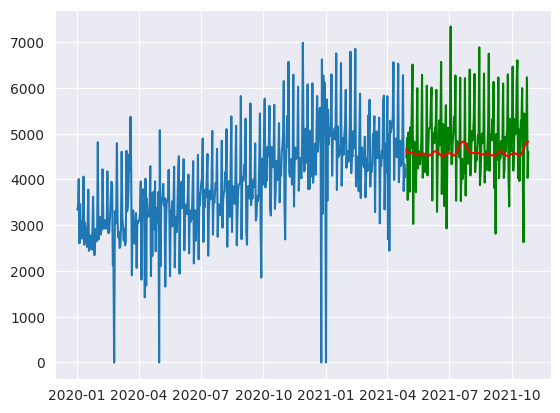

In [ ]:
# Gerando as previsões
y_predict = res.predict(start=df_mt.index.min(), end=df_mt.index.max(), exog=exog_test_sarimax)
#plot dos resultados
plt.plot(df_m.QUANTIDADE)
plt.plot(df_mt.QUANTIDADE, color='green')
plt.plot(y_predict,color= 'red')

In [ ]:
# The line below created a self-referential series, causing a recursion error.
# y_predict['pred'] = y_predict
# y_predict is already a pandas Series with the predictions.

In [ ]:
calculo_erro(y_predict, df_mt.QUANTIDADE)

       MÉTRICAS DE ERRO       
  MAPE: 13.17%
  MAE:  638.10


{'MAPE': 0.13171815170828166, 'MAE': np.float64(638.1029305062046)}

In [ ]:
# ajuste do dataset de treino e teste
train_prophet = df_train[['QUANTIDADE']].reset_index()
train_prophet.columns = ['ds', 'y']
test_prophet = df_test[['QUANTIDADE']].reset_index()
test_prophet.columns = ['ds', 'y']
train_prophet.head()

,ds,y
0,2020-01-02,3340.0
1,2020-01-03,3420.0
2,2020-01-04,4010.0
3,2020-01-05,2605.0
4,2020-01-06,3461.0


In [ ]:
# instancia prophet e treina
m = Prophet(yearly_seasonality = True)
m.add_country_holidays(country_name='BR')
m.fit(train_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


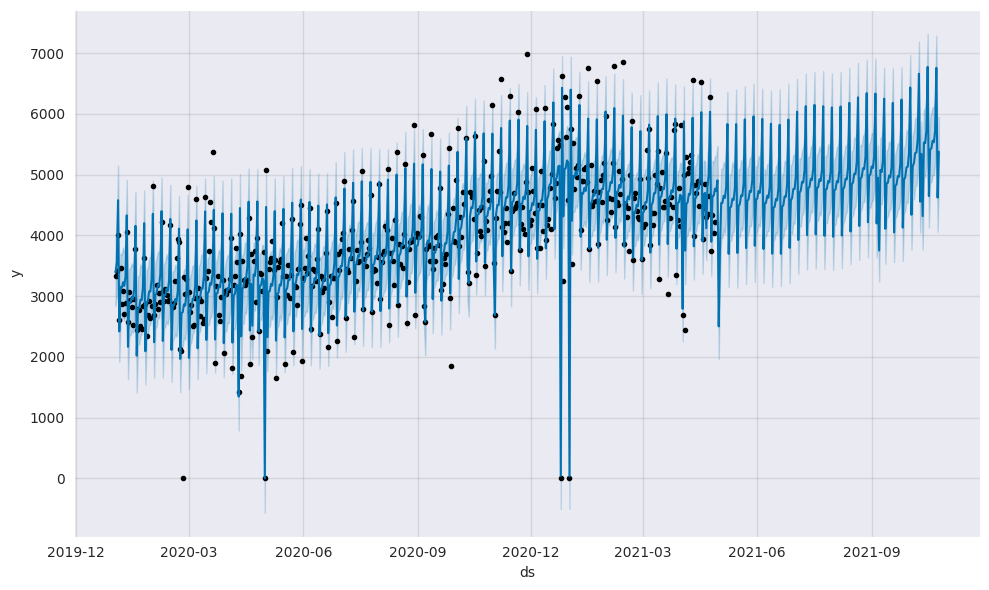

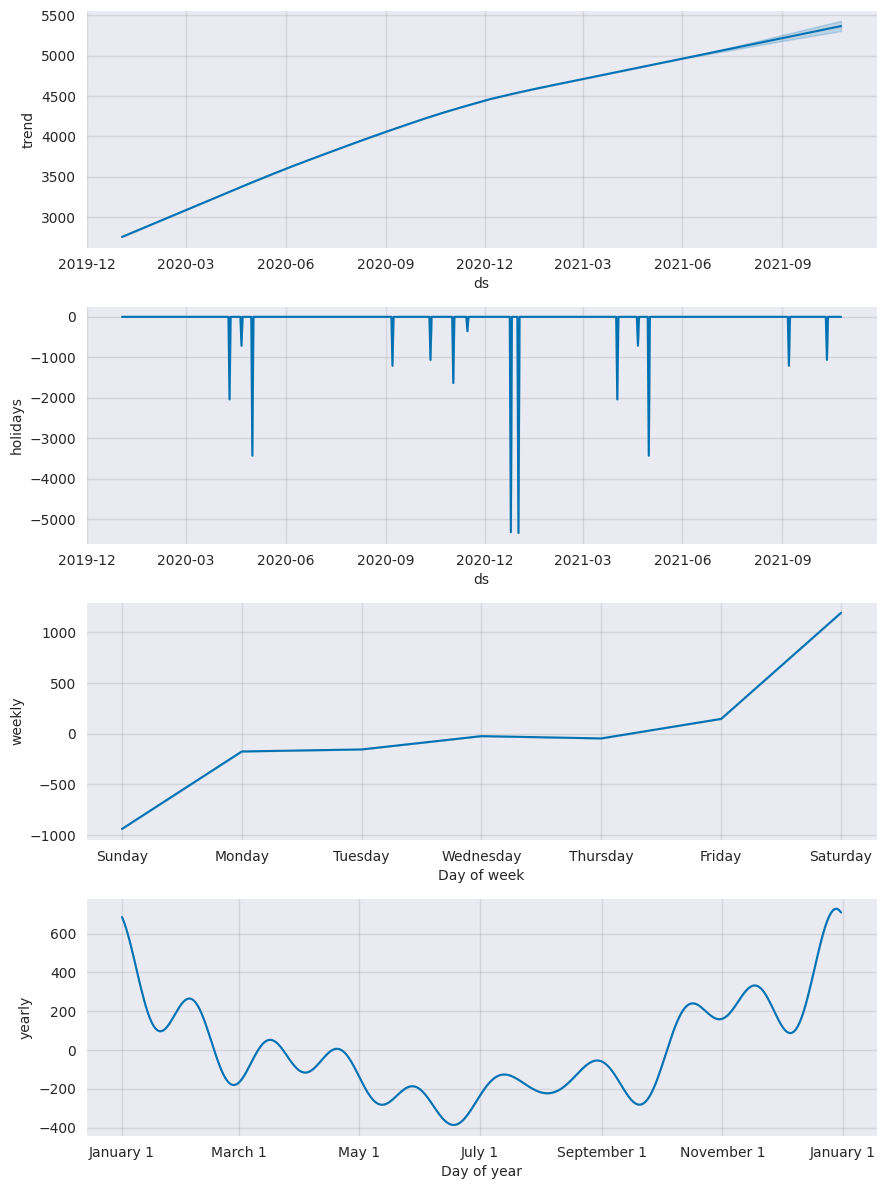

In [ ]:
# construção do dataset de teste para alimentar o modelo
future = m.make_future_dataframe(periods=len(df_test))

# realiza previsão
forecast = m.predict(future)

#plota previsão
m.plot(forecast);

#plota componentes
m.plot_components(forecast);

In [ ]:
prophet_ds = forecast.set_index('ds')[['yhat', 'yhat_lower', 'yhat_upper']].join(test_prophet.set_index('ds'))

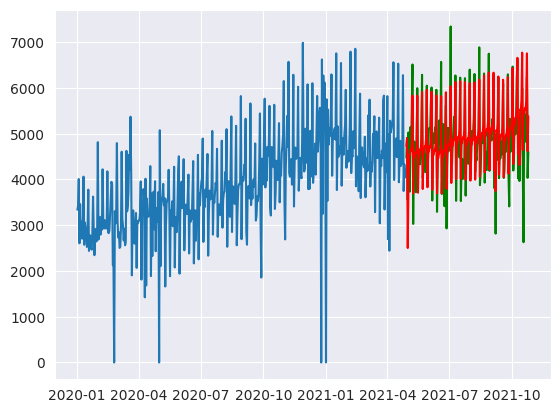

In [ ]:
# plot dos resultados
plt.plot(df_train.QUANTIDADE)
plt.plot(df_test.QUANTIDADE, color='green')
plt.plot(prophet_ds['yhat'].tail(180), color='red')

In [ ]:
prophet_pred_real = prophet_ds[~prophet_ds.y.isna()]

In [ ]:
calculo_erro(prophet_pred_real.yhat, prophet_pred_real.y)

       MÉTRICAS DE ERRO       
  MAPE: 8.33%
  MAE:  365.84


{'MAPE': 0.08327104908565329, 'MAE': np.float64(365.84410740823085)}

## Resultado

O modelo que melhor performou foi o Prophet: MAPE: 8.33% e MAE: 365,84

---

# Deploy
Agora, vamos utilizar o modelo para ser utilizado durante a produção (dia a dia)


In [ ]:
import pickle
from prophet import Prophet
from datetime import datetime

# ── Configurações ──────────────────────────────────────
MODEL_PATH   = "prophet_farmasaude.pkl"
HORIZON_DAYS = 180  # ~6 meses

# ── Retreino ───────────────────────────────────────────
def retreinar_modelo(df):
    """df deve ter colunas 'ds' e 'y' — já no formato do seu notebook"""
    print(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] Iniciando retreino...")
    print(f"  Período: {df['ds'].min().date()} → {df['ds'].max().date()}")

    m = Prophet(yearly_seasonality=True, weekly_seasonality=True,
                daily_seasonality=False, seasonality_mode="additive")
    m.add_country_holidays(country_name="BR")
    m.fit(df)

    with open(MODEL_PATH, "wb") as f:
        pickle.dump(m, f)

    print(f"  Modelo salvo em: {MODEL_PATH}")
    return m

# ── Previsão ───────────────────────────────────────────
def prever(model, horizon_days=HORIZON_DAYS):
    print(f"\n[{datetime.now():%Y-%m-%d %H:%M:%S}] Gerando previsão para {horizon_days} dias...")

    future   = model.make_future_dataframe(periods=horizon_days, freq="D")
    forecast = model.predict(future)

    resultado = (
        forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]]
        .tail(horizon_days)
        .rename(columns={"ds": "Data", "yhat": "Previsao",
                         "yhat_lower": "Limite_Inferior", "yhat_upper": "Limite_Superior"})
        .reset_index(drop=True)
    )

    for col in ["Previsao", "Limite_Inferior", "Limite_Superior"]:
        resultado[col] = resultado[col].clip(lower=0).round(0).astype(int)

    print(f"  Horizonte: {resultado['Data'].min().date()} → {resultado['Data'].max().date()}")
    print(f"  Média diária: {resultado['Previsao'].mean():,.0f} unidades")
    print(f"  Total no período: {resultado['Previsao'].sum():,.0f} unidades")

    return resultado

# ── Execução ───────────────────────────────────────────
# train_prophet já existe no seu notebook com colunas 'ds' e 'y'
model     = retreinar_modelo(train_prophet)
resultado = prever(model)
resultado.head()

[2026-03-08 17:37:40] Iniciando retreino...
  Período: 2020-01-02 → 2021-04-28
  Modelo salvo em: prophet_farmasaude.pkl

[2026-03-08 17:37:41] Gerando previsão para 180 dias...
  Horizonte: 2021-04-29 → 2021-10-25
  Média diária: 4,931 unidades
  Total no período: 887,550 unidades


,Data,Previsao,Limite_Inferior,Limite_Superior
0,2021-04-29,4731,4196,5311
1,2021-04-30,4906,4314,5427
2,2021-05-01,2503,1947,3012
3,2021-05-02,3787,3246,4354
4,2021-05-03,4533,3975,5126
